<div align="left" style="background-color: #008080; padding: 20px 10px;">
<h3><b style="color: white;">IDEAS - Institute of Data Engineering, Analytics and Science Foundation</b></h3>
<p style="color: white;">Autumn Internship Program 2026</p>
<hr style="width:75%; background-color: white; border-color: white;">
<h3 style="color: white;">Project Title: E-Commerce Customer Conversion Analytics</h3>
<h4 style="color: white;">Mentor Name: Dr. Chandan Biswas</h4>
</div>

### Question 1: Data Ingestion and Schema Inspection (5 Marks)

Load the 'Online Shoppers Purchasing Intention' dataset directly from the UCI Machine Learning Repository (`https://archive.ics.uci.edu/ml/machine-learning-databases/00468/online_shoppers_intention.csv`). Once loaded into a pandas DataFrame, display the structural information of the dataset and calculate the total number of missing values for each column. Finally, use a `print()` statement to output a brief observation about the overall size and data types present in the dataset.

**Hint:** Utilize the standard pandas read function to fetch the data. The structural summary and null-counting methods will provide the necessary schema metrics.

**Expected Output:** A printed summary showing the total number of entries, the data type of each column, a tabular list indicating the count of null values per feature, and a brief written observation.

In [19]:
# Write your answer here
import pandas as pd
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00468/online_shoppers_intention.csv"
df = pd.read_csv(url) #download and loads the files.
print("DATA STRUCTURE")
df.info() #prints the row count and each column's data type.
print("MISSING VALUES PER COLUMN")
df.isnull().sum() #counts the empty cells in each column
n_rows, n_cols = df.shape
n_numeric = df.select_dtypes(include="number").shape[1]
n_other = n_cols - n_numeric
print(f"The dataset has {n_rows} entries and {n_cols} columns."
f"{n_numeric} columns are numeric and {n_other} are non-numeric"
f"(text or boolean, such as month, visitortype, weekend and revenue)."
f"There are {df.isnull().sum()} missing values in total,"
f"so the data is largely complete. ")


DATA STRUCTURE
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  Traffic

### Question 2: Missing Value and Duplicate Treatment (6 Marks)

Identify and remove any exact duplicate rows in the dataset. Following this, handle any remaining missing values by applying median imputation for numerical columns and mode imputation for categorical columns. Use a Python `print()` statement to justify why imputation was chosen over simply dropping the rows with missing values in this specific context.

**Hint:** Sequentially drop exact duplicates, then apply appropriate central tendency metrics for nulls based on data types. Use standard print output to explain your rationale.

**Expected Output:** A clean pandas DataFrame with a reduced row count, zero remaining missing values across all columns, and a printed analytical justification.

In [20]:
# Write your answer here
rows_before = df.shape[0]
print("Duplicate rows found:", df.duplicated().sum()) #counts rows that repeat an earlier row.

df = df.drop_duplicates() #removes the duplicates

rows_after =df.shape[0]
print(f"Rows before: {rows_before} / Rows after: {rows_after} / Removed: {rows_before - rows_after}")
#to split the columns into numeric ones and the rest
num_cols = df.select_dtypes(include="number").columns
cat_cols = df.select_dtypes(exclude="number").columns
for col in num_cols:
  df[col] = df[col].fillna(df[col].mode()[0]) #fillna(value) fills empty cells
print("\n Remaining missing values:", df.isnull().sum().sum())
print("\nJustification")
print(f"Imputation was chosen over dropping rows because every row is a real "
f"customer session. Deleting rows with missing values would throw away the "
f"other valid information in those rows and shrink an already imbalanced "
f"dataset, since purchases are a small minority. Median is used for numeric "
f"columns because durations and counts are right-skewed and the median is "
f"robust to extreme values, and mode is used for categorical columns because "
f"the most frequent category is the only sensible 'average' for text labels.")

Duplicate rows found: 125
Rows before: 12330 / Rows after: 12205 / Removed: 125

 Remaining missing values: 0

Justification
Imputation was chosen over dropping rows because every row is a real customer session. Deleting rows with missing values would throw away the other valid information in those rows and shrink an already imbalanced dataset, since purchases are a small minority. Median is used for numeric columns because durations and counts are right-skewed and the median is robust to extreme values, and mode is used for categorical columns because the most frequent category is the only sensible 'average' for text labels.


### Question 3: Outlier Detection and Treatment (6 Marks)

Calculate the Interquartile Range (IQR) for the `Administrative_Duration` and `ProductRelated_Duration` columns. Use this metric to cap (winsorize) the outliers at the upper bound (Q3 + 1.5 * IQR). Use a `print()` statement to explain the statistical benefit of capping extreme values rather than deleting them for this dataset.

**Hint:** Calculate the 25th (Q1) and 75th (Q3) percentiles to determine the upper bound. Reassign values exceeding this threshold to the upper bound itself. Print a brief defense of this technique.

**Expected Output:** A modified DataFrame where extreme anomalies in duration columns are contained within calculated upper bounds, accompanied by a printed explanation of the method's validity.

In [21]:
# Write your answer here
cols = ["Administrative_Duration", "ProductRelated_Duration"]
for col in cols:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1
  upper_bound = Q3 + 1.5 * IQR

  n_outliers = (df[col] > upper_bound).sum()
  df.loc[df[col] > upper_bound, col] = upper_bound

  print(f"{col}: Q1={Q1:.2f}, Q3={Q3:.2f}, IQR={IQR:.2f}, "
  f"upper bound={upper_bound:.2f}, values capped={n_outliers}")

print("\n=== JUSTIFICATION ===")
print("Capping is preferred over deleting because every row is a real customer "
      "session, and the heaviest browsers are often the most valuable buyers, so "
      "deleting them would remove exactly the customers we want to understand and "
      "would shrink the minority purchase class further . Capping keeps all rows "
      "while limiting the influence of the extreme durations on scaling,K-Means "
      "distances and linear models, which are sensitive to extreme values.")

Administrative_Duration: Q1=0.00, Q3=94.70, IQR=94.70, upper bound=236.75, values capped=1149
ProductRelated_Duration: Q1=193.00, Q3=1477.15, IQR=1284.15, upper bound=3403.39, values capped=951

=== JUSTIFICATION ===
Capping is preferred over deleting because every row is a real customer session, and the heaviest browsers are often the most valuable buyers, so deleting them would remove exactly the customers we want to understand and would shrink the minority purchase class further . Capping keeps all rows while limiting the influence of the extreme durations on scaling,K-Means distances and linear models, which are sensitive to extreme values.


### Question 4: Correlation Analysis (7 Marks)

Assess the linear relationships among the numerical variables to identify potential multicollinearity. Generate a correlation matrix for all continuous numerical features and visualize it using an annotated heatmap. Use a `print()` statement to identify which specific pairs of variables exhibit high correlation and suggest a reason why.

**Hint:** Filter the DataFrame for numerical datatypes, compute the correlation matrix, and visualize it using a standard statistical plotting library. Print your observations regarding variable pairs.

**Expected Output:** A visual heatmap graphic displaying correlation coefficients, and a printed sentence identifying potential multicollinearity among specific features.

Highly correlated pairs (|r| > 0.7):
 Administrative & Administrative_Duration: r = 0.79
 ProductRelated & ProductRelated_Duration: r = 0.74
 BounceRates & ExitRates: r = 0.90

=== Observation ===
BounceRates and ExitRates are strongly correlated because both measure how often visitors leave the site, so a page with a high bounce rate naturally has a high exit rate. ProductRelated and ProductRelated_Duration are also strongly correlated because viewing more product pages mechanically means spending more time on them. These pairs are potential multicollinearity and carry overlapping information.


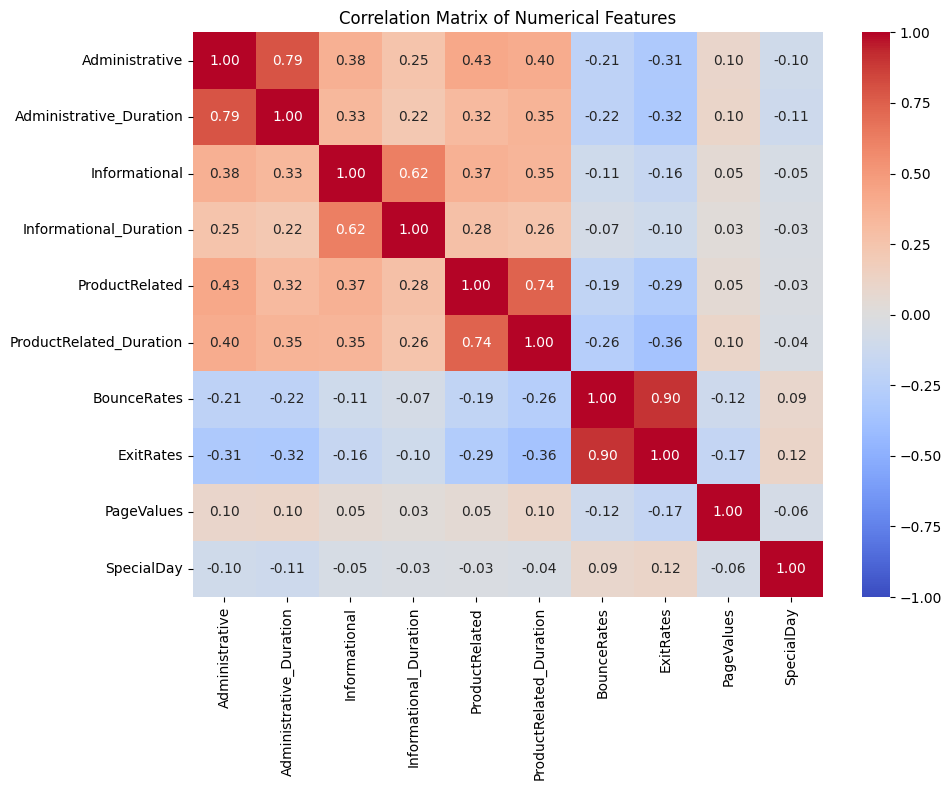

In [22]:
# Write your answer here
import matplotlib.pyplot as plt
import seaborn as sns
cont_cols = ["Administrative", "Administrative_Duration",
             "Informational", "Informational_Duration",
             "ProductRelated", "ProductRelated_Duration",
             "BounceRates", "ExitRates", "PageValues", "SpecialDay"]
corr = df[cont_cols].corr()

plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show

threshold = 0.7
print(f"Highly correlated pairs (|r| > {threshold}):")
for i in range(len(corr.columns)):
  for j in range(i + 1, len(corr.columns)):
    r = corr.iloc[i,j]
    if abs(r) > threshold:
      print(f" {corr.columns[i]} & {corr.columns[j]}: r = {r:.2f}")

print("\n=== Observation ===")
print("BounceRates and ExitRates are strongly correlated because both measure "
      "how often visitors leave the site, so a page with a high bounce rate "
      "naturally has a high exit rate. ProductRelated and "
      "ProductRelated_Duration are also strongly correlated because viewing more "
      "product pages mechanically means spending more time on them. These pairs "
      "are potential multicollinearity and carry overlapping information.")

### Question 5: Unsupervised Customer Segmentation (7 Marks)

Prior to supervised modeling, explore underlying patterns by applying K-Means clustering to the continuous numerical features to form 4 distinct customer segments. Append the resulting cluster labels to your DataFrame as a new categorical column named `Customer_Segment`. Use a `print()` statement to explain what behavioral patterns this unsupervised step attempts to capture.

**Hint:** Initialize the clustering algorithm with 4 clusters and a fixed random state. Apply the fit-predict method to generate labels and append them to your DataFrame. Print your analytical reasoning.

**Expected Output:** The main DataFrame updated with a new categorical column for cluster assignments, accompanied by a printed conceptual explanation.

In [23]:
# Write your answer here
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

cont_cols = ["Administrative", "Administrative_Duration",
             "Informational", "Informational_Duration",
             "ProductRelated", "ProductRelated_Duration",
             "BounceRates", "ExitRates", "PageValues", "SpecialDay"]

X_cluster = StandardScaler().fit_transform(df[cont_cols])

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df["Customer_Segement"] = kmeans.fit_predict(X_cluster)

df["Customer_Segement"] = df["Customer_Segement"].astype("category")

print("Customer per segement:")
print(df["Customer_Segement"].value_counts().sort_index())

print("\nAverage behaviour per segement:")
print(df.groupby("Customer_Segement", observed=True)[["ProductRelated", "ProductRelated_Duration",
                                                      "BounceRates", "ExitRates", "PageValues"]].mean().round(2))

print("\n=== Explanation ===")
print("K-Means groups visitors by similarity in browsing behaviour without using "
      "the purchase label. It tries to capture patterns such as quick-exit "
      "visitors with high bounce and exit rates, highly engaged shoppers who view "
      "many product pages for a long time, and visitors who generate high page "
      "value. These behavioural segments give the later supervised models extra "
      "information about visitor intent.")

Customer per segement:
Customer_Segement
0     919
1    7581
2    2964
3     741
Name: count, dtype: int64

Average behaviour per segement:
                   ProductRelated  ProductRelated_Duration  BounceRates  \
Customer_Segement                                                         
0                            3.24                    60.49         0.16   
1                           20.18                   711.90         0.01   
2                           51.62                  1657.12         0.01   
3                          110.83                  2506.20         0.01   

                   ExitRates  PageValues  
Customer_Segement                         
0                       0.18        0.00  
1                       0.04        4.13  
2                       0.02       11.80  
3                       0.02        8.50  

=== Explanation ===
K-Means groups visitors by similarity in browsing behaviour without using the purchase label. It tries to capture patterns such as

### Question 6: Categorical Encoding (6 Marks)

Convert the target variable `Revenue` into a binary integer format (1 for True, 0 for False). Apply one-hot encoding to the remaining nominal categorical features (e.g., `Month`, `VisitorType`, `Weekend`, and the newly created `Customer_Segment`).

**Hint:** Cast the boolean target to an integer type. Apply dummy variable creation with the drop-first parameter enabled to format all other textual or categorical representations.

**Expected Output:** A fully numerical DataFrame structured for modeling, containing newly generated binary columns representing the various categories of the original features.

In [24]:
# Write your answer here
if "Customer_Segement" in df.columns:
  df = df.rename(columns={"Customer_Segement": "Customer_Segement"})

df_encoded = df.copy()

df_encoded["Revenue"] = df_encoded["Revenue"].astype(int)

cat_features = ["Month", "VisitorType", "Weekend", "Customer_Segement"]
df_encoded = pd.get_dummies(df_encoded, columns=cat_features, drop_first=True, dtype=int)

print("Shape after encoding:", df_encoded.shape)
print("\nColumn data types:")
print(df_encoded.dtypes.value_counts())
print("\nNew Columns created:")
print([c for c in df_encoded.columns if c.startswith(("Month_", "VisitorType_", "Customer_Segement_"))])
print("\nTarget distribution (Revenue):")
print(df_encoded["Revenue"].value_counts())
df_encoded.head()

Shape after encoding: (12205, 30)

Column data types:
int64      23
float64     7
Name: count, dtype: int64

New Columns created:
['Month_Dec', 'Month_Feb', 'Month_Jul', 'Month_June', 'Month_Mar', 'Month_May', 'Month_Nov', 'Month_Oct', 'Month_Sep', 'VisitorType_Other', 'VisitorType_Returning_Visitor', 'Customer_Segement_1', 'Customer_Segement_2', 'Customer_Segement_3']

Target distribution (Revenue):
Revenue
0    10297
1     1908
Name: count, dtype: int64


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,Month_May,Month_Nov,Month_Oct,Month_Sep,VisitorType_Other,VisitorType_Returning_Visitor,Weekend_True,Customer_Segement_1,Customer_Segement_2,Customer_Segement_3
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,0,0,0,0,0,1,0,0,0,0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,...,0,0,0,0,0,1,0,1,0,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,0,0,0,0,0,1,0,0,0,0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,...,0,0,0,0,0,1,0,1,0,0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,...,0,0,0,0,0,1,1,1,0,0


### Question 7: Feature Scaling and Data Splitting (7 Marks)

Separate the dataset into a feature matrix `X` and a target vector `y`. Split these into training and testing sets utilizing an 80/20 ratio and a random state of 42. Following the split, apply standardization to the feature matrices. You must explicitly convert the resulting scaled NumPy arrays back into Pandas DataFrames, retaining the original column names for interpretability later in the pipeline.

**Hint:** Separate target and features, then perform the split. Fit the standard scaler strictly on the training features. After transforming both sets, reconstruct them as pandas DataFrames using the original columns.

**Expected Output:** Scaled training and testing pandas DataFrames preserving column names, along with the respective target arrays.

In [25]:
# Write your answer here
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df_encoded.drop("Revenue", axis=1)
Y = df_encoded["Revenue"]

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X.columns, index=X_test.index)

print("X_train:", X_train_scaled.shape, "| X_test:", X_test_scaled.shape)
print("Y_train:", Y_train.shape, "| Y_test:", Y_test.shape)
print("\nTraining class distribution (%):")
print((Y_train.value_counts(normalize=True) * 100).round(1))
X_train_scaled.head()

X_train: (9764, 29) | X_test: (2441, 29)
Y_train: (9764,) | Y_test: (2441,)

Training class distribution (%):
Revenue
0    84.2
1    15.8
Name: proportion, dtype: float64


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,Month_May,Month_Nov,Month_Oct,Month_Sep,VisitorType_Other,VisitorType_Returning_Visitor,Weekend_True,Customer_Segement_1,Customer_Segement_2,Customer_Segement_3
5304,-0.701239,-0.722207,-0.399102,-0.251143,-0.583839,-0.839842,-0.450980,-0.174528,-0.320068,-0.306329,...,1.644414,-0.574354,-0.217491,-0.193673,-0.081228,-2.427059,-0.551161,0.782997,-0.568204,-0.254056
9686,-0.701239,-0.722207,-0.399102,-0.251143,1.228007,0.191501,-0.450980,-0.846356,1.677195,-0.306329,...,-0.608119,1.741086,-0.217491,-0.193673,-0.081228,-2.427059,-0.551161,0.782997,-0.568204,-0.254056
11085,1.398760,1.699641,0.374233,0.266853,-0.382523,-0.535723,-0.450980,-0.557215,-0.320068,-0.306329,...,-0.608119,-0.574354,-0.217491,-0.193673,-0.081228,0.412021,-0.551161,-1.277144,1.759931,-0.254056
7515,1.398760,2.227685,-0.399102,-0.251143,-0.404891,-0.636902,0.873772,0.928773,-0.320068,-0.306329,...,-0.608119,-0.574354,-0.217491,-0.193673,-0.081228,0.412021,-0.551161,-1.277144,1.759931,-0.254056
6717,-0.701239,-0.722207,-0.399102,-0.251143,-0.561471,0.698575,0.395080,-0.060937,-0.320068,-0.306329,...,-0.608119,1.741086,-0.217491,-0.193673,-0.081228,0.412021,-0.551161,0.782997,-0.568204,-0.254056


### Question 8: Class Imbalance Handling (6 Marks)

Address the class imbalance in the training set using the Synthetic Minority Over-sampling Technique (SMOTE). Use a Python `print()` statement to explain why training a model on imbalanced conversion data can lead to misleading accuracy metrics.

**Hint:** Import the synthetic minority over-sampling module. Apply it exclusively to your scaled training features and training target. Print a brief explanation regarding the risks of imbalanced datasets.

**Expected Output:** Resampled training feature and target arrays that demonstrate an equal distribution of instances, plus a printed analytical statement.

In [26]:
# Write your answer here
from imblearn.over_sampling import SMOTE
print("Before SMOTE:")
print(Y_train.value_counts())

smote = SMOTE(random_state=42)
X_train_res, Y_train_res = smote.fit_resample(X_train_scaled, Y_train)

print("\nAfter SMOTE:")
print(Y_train_res.value_counts())
print("Resampled training features:", X_train_res.shape)

print("\n=== Explanation ===")
print("With imbalanced conversion data, a model can reach high accuracy simply by "
      "predicting 'no purchase' for almost every visitor, because non-buyers make "
      "up about 84% of the data. That accuracy hides the fact that the model "
      "misses most real buyers, which are the customers the business cares about. "
      "Balancing the training set with SMOTE forces the model to learn the "
      "patterns of buyers, and metrics such as recall, F1 and ROC-AUC should be "
      "used alongside accuracy.")

Before SMOTE:
Revenue
0    8218
1    1546
Name: count, dtype: int64

After SMOTE:
Revenue
0    8218
1    8218
Name: count, dtype: int64
Resampled training features: (16436, 29)

=== Explanation ===
With imbalanced conversion data, a model can reach high accuracy simply by predicting 'no purchase' for almost every visitor, because non-buyers make up about 84% of the data. That accuracy hides the fact that the model misses most real buyers, which are the customers the business cares about. Balancing the training set with SMOTE forces the model to learn the patterns of buyers, and metrics such as recall, F1 and ROC-AUC should be used alongside accuracy.


### Question 9: Baseline Logistic Regression Implementation (5 Marks)

Construct a baseline Logistic Regression model. Train this model using the SMOTE-balanced training data and generate classification predictions on the unseen test set.

**Hint:** Instantiate the linear classification model, fit it to the balanced training dataset, and generate an array of predictions using the test features.

**Expected Output:** A trained standard classification model object in memory and a 1-dimensional array of binary class predictions for the test dataset.

In [27]:
# Write your answer here
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(max_iter=1000, random_state=42)

log_reg.fit(X_train_res, Y_train_res)

Y_pred_lr = log_reg.predict(X_test_scaled)

print("Model trained:", log_reg)
print("Predictions shape:", Y_pred_lr.shape)
print("First 10 predicions:", Y_pred_lr[:10])
print("Predicted buyers (1):", Y_pred_lr.sum(), "out of", len(Y_pred_lr))

Model trained: LogisticRegression(max_iter=1000, random_state=42)
Predictions shape: (2441,)
First 10 predicions: [0 1 0 0 0 0 0 0 0 0]
Predicted buyers (1): 522 out of 2441


### Question 10: Baseline Random Forest Classification (5 Marks)

Construct and train a baseline Random Forest Classifier on the balanced training data and generate test set predictions.

**Hint:** Instantiate a random forest classifier with a defined number of estimators and fixed random state. Fit the model and predict the outcomes for the test set.

**Expected Output:** A trained tree-based ensemble model object in memory and a 1-dimensional array of discrete binary predictions.

In [28]:
# Write your answer here
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42)

rf.fit(X_train_res, Y_train_res)

Y_pred_rf = rf.predict(X_test_scaled)

print("Model trained:", rf)
print("Predictions shape:", Y_pred_rf.shape)
print("First 10 predictions:", Y_pred_rf[:10])
print("Predicted buyers (1):", Y_pred_rf.sum(), "out of", len(Y_pred_rf))

Model trained: RandomForestClassifier(random_state=42)
Predictions shape: (2441,)
First 10 predictions: [0 1 0 0 0 0 0 0 0 1]
Predicted buyers (1): 402 out of 2441


### Question 11: Cross-Validation and Hyperparameter Tuning (9 Marks)

Optimize the Random Forest model architecture using an exhaustive search over specified parameter values. Configure a grid search to test combinations of `n_estimators` (e.g., 50, 100) and `max_depth` (e.g., None, 10, 20) utilizing 5-fold cross-validation.

**Hint:** Define a dictionary mapping the parameters to their search space. Pass this dictionary and the Random Forest estimator to the cross-validation search module, then execute the fit process.

**Expected Output:** An optimized model object containing the most effective combination of parameters identified during the cross-validation process.

In [29]:
# Write your answer here
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

param_grid = {
    "n_estimators": [50,100],
    "max_depth": [None, 10, 20]
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

grid_search.fit(X_train_res, Y_train_res)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validated ROC-AUC:", round(grid_search.best_score_, 4))

best_rf = grid_search.best_estimator_
print("\nTuned model:", best_rf)

Best parameters: {'max_depth': None, 'n_estimators': 100}
Best cross-validated ROC-AUC: 0.9861

Tuned model: RandomForestClassifier(random_state=42)


### Question 12: Metric Evaluation (ROC-AUC) (7 Marks)

Evaluate the diagnostic ability of the tuned Random Forest model using threshold-independent metrics. Calculate the ROC-AUC score and plot the corresponding Receiver Operating Characteristic (ROC) curve.

**Hint:** Compute positive class probabilities. Generate the area under the curve score and plot the true positive rate versus false positive rate.

**Expected Output:** A floating-point number representing the area under the curve, alongside a 2D line plot charting the evaluation metric.

ROC-AUC (tuned Random Forest, test set): 0.921911


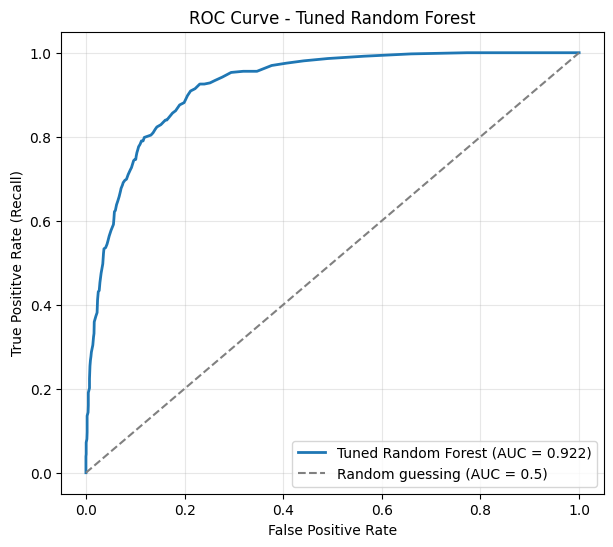

In [30]:
# Write your answer here
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

Y_prob_rf = best_rf.predict_proba(X_test_scaled)[:, 1]

auc_rf = roc_auc_score(Y_test, Y_prob_rf)
print(f"ROC-AUC (tuned Random Forest, test set): {auc_rf:4f}")

fpr, tpr, thresholds = roc_curve(Y_test, Y_prob_rf)

plt.figure(figsize=(7,6))
plt.plot(fpr, tpr, linewidth=2, label=f"Tuned Random Forest (AUC = {auc_rf:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guessing (AUC = 0.5)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Posititve Rate (Recall)")
plt.title("ROC Curve - Tuned Random Forest")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

### Question 13: Multi-Layer Perceptron (MLP) Implementation (7 Marks)

Establish a Multi-Layer Perceptron (MLP) neural network to compare against the ensemble approach. Construct the network with two hidden layers (64 and 32 neurons respectively), utilize the ReLU activation function, and train the model on the balanced dataset. Use a Python `print()` statement to provide a brief conceptual primer on why an MLP architecture is being tested here.

**Hint:** Construct the neural network specifying the hidden layer sizes and activation function. Set a maximum iteration limit to ensure convergence. Print a sentence explaining the theoretical advantage of using an MLP to capture complex, non-linear relationships.

**Expected Output:** A converged neural network classifier object capable of predicting the binary target, and a printed conceptual primer.

In [31]:
# Write your answer here
from sklearn.neural_network import MLPClassifier

print("=== Why an MLP? ===")

print("Logistic Regression can only learn linear decision boundaries, and "
      "Random Forests split the data with axis-aligned rules. An MLP stacks "
      "layers of neurons with a non-linear ReLU activation, so it can learn "
      "complex, non-linear interactions between features, such as how "
      "page values, exit rates and visitor type combine to signal purchase "
      "intent. Testing it shows whether this extra flexibility beats the "
      "ensemble approach on this dataset.")

mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    max_iter=500,
    random_state=42
)

mlp.fit(X_train_res, Y_train_res)
Y_pred_mlp = mlp.predict(X_test_scaled)
Y_prob_mlp = mlp.predict_proba(X_test_scaled)[:, 1]

print("\nIterations run:", mlp.n_iter_, "(limit: 500)")
print("Predictions shape:", Y_pred_mlp.shape)
print("Predicted buyers (1):", Y_pred_mlp.sum(), "out of", len(Y_pred_mlp))

=== Why an MLP? ===
Logistic Regression can only learn linear decision boundaries, and Random Forests split the data with axis-aligned rules. An MLP stacks layers of neurons with a non-linear ReLU activation, so it can learn complex, non-linear interactions between features, such as how page values, exit rates and visitor type combine to signal purchase intent. Testing it shows whether this extra flexibility beats the ensemble approach on this dataset.

Iterations run: 249 (limit: 500)
Predictions shape: (2441,)
Predicted buyers (1): 423 out of 2441


### Question 14: Feature Importance Analysis (7 Marks)

Extract the internal feature importance scores from the tuned Random Forest model and create a horizontal bar chart of the top 10 most influential predictors. Use a `print()` statement to interpret what the highest-ranking feature suggests about customer behavior.

**Hint:** Access the importance attribute from the optimal tree model. Pair these with column names from your scaled DataFrame, sort them, and visualize using a standard plotting library. Print a brief interpretation of the top feature.

**Expected Output:** A sorted horizontal bar chart visually demonstrating influential predictors, alongside a printed analytical sentence.

Top 10 features:
PageValues                       0.4222
ExitRates                        0.0748
Administrative                   0.0661
ProductRelated_Duration          0.0611
ProductRelated                   0.0510
BounceRates                      0.0436
Administrative_Duration          0.0425
TrafficType                      0.0404
OperatingSystems                 0.0295
Region                           0.0291
Month_Nov                        0.0251
Browser                          0.0239
Informational                    0.0185
Informational_Duration           0.0161
VisitorType_Returning_Visitor    0.0082
Weekend_True                     0.0075
Month_May                        0.0072
Customer_Segement_1              0.0044
Month_Dec                        0.0041
SpecialDay                       0.0040
Month_Mar                        0.0040
Customer_Segement_2              0.0039
Month_Jul                        0.0030
Month_Oct                        0.0030
Month_Sep              

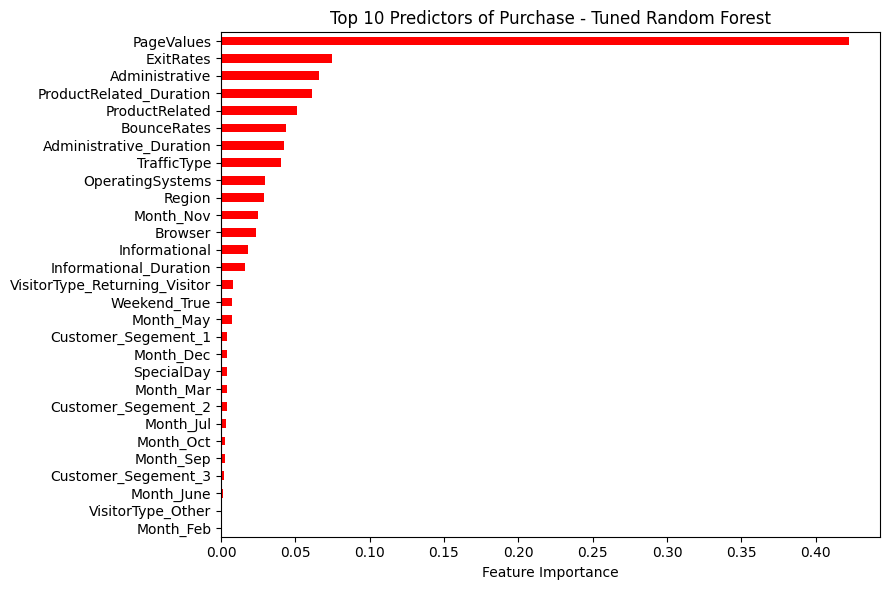


=== Interpretation ===
The most influential feature is PageValues.
PageValues is the average value of the pages a visitor viewed before completing a transaction, so a high value means the visitor reached pages that typically lead to purchases. Its dominance suggests that conversion depends mostly on whether a visitor reaches high-value pages such as product and checkout pages, more than on how long they browse.


In [32]:
# Write your answer here
import pandas as pd
import matplotlib.pyplot as plt

importances = pd.Series(best_rf.feature_importances_, index=X_train_scaled.columns)

top10 = importances.sort_values(ascending=False)
print("Top 10 features:")
print(top10.round(4))

plt.figure(figsize=(9, 6))
top10.sort_values().plot(kind="barh", color="red")
plt.xlabel("Feature Importance")
plt.title("Top 10 Predictors of Purchase - Tuned Random Forest")
plt.tight_layout()
plt.show()

top_feature = top10.index[0]
print("\n=== Interpretation ===")
print(f"The most influential feature is {top_feature}.")
print("PageValues is the average value of the pages a visitor viewed before "
      "completing a transaction, so a high value means the visitor reached "
      "pages that typically lead to purchases. Its dominance suggests that "
      "conversion depends mostly on whether a visitor reaches high-value pages "
      "such as product and checkout pages, more than on how long they browse.")

### Question 15: Business Impact and Expected Value Formulation (10 Marks)

Translate model metrics into projected financial performance. Assume retaining a customer via a targeted campaign generates a net revenue of $50, while the cost of applying the campaign to any predicted positive is $10. Calculate the total expected financial impact of deploying your tuned Random Forest model on the test set. Use a Python `print()` statement to output the final monetary value and provide a brief recommendation on whether the business should deploy this model.

**Hint:** Extract True Positives (TP) and False Positives (FP) from a confusion matrix. Apply the formula where total profit equals revenue gained from true positives minus the intervention cost spent on all positive predictions. Print the calculated monetary result and your recommendation.

**Expected Output:** A calculated confusion matrix structure, and a printed monetary value representing the projected aggregate net profit, accompanied by a concluding business recommendation.

In [33]:
# Write your answer here
from sklearn.metrics import confusion_matrix

REVENUE_PER_SUCCESS = 50
COST_PER_CAMPAIGN = 10

Y_pred_best = best_rf.predict(X_test_scaled)

cm = confusion_matrix(Y_test, Y_pred_best)
TN, FP, FN, TP = cm.ravel()
print("Confusion matrix:")
print(cm)
print(f"TP={TP}, FP={FP}, FN={FN}, TN={TN}")

campaigns_sent = TP + FP
profit = REVENUE_PER_SUCCESS * TP - COST_PER_CAMPAIGN *campaigns_sent
precision = TP / campaigns_sent

print(f"\nCampaigns sent: {campaigns_sent}")
print(f"Precision: {precision:.1%} (break-even is 20%)")
print(f"Total expected net profit: ${profit:,.2f}")

profit_all = REVENUE_PER_SUCCESS * (TP + FN) - COST_PER_CAMPAIGN * len(Y_test)
print(f"Profit if everyone were targeted (no model): ${profit_all:,.2f}")

print("\n=== Recomendation ===")
if profit > 0:
  print(f"The model generates a projected net profit of ${profit:,.2f} on the "
        f"test set, because {precision:.1%} of targeted customers convert, above "
        f"the 20% break-even point. Targeting everyone would give "
        f"${profit_all:,.2f}, so the model adds clear value by focusing the "
        f"campaign on likely buyers. I recommend deploying it, with periodic "
        f"monitoring because customer behaviour changes over time.")
else:
  print(f"The model gives a net loss of ${profit:,.2f}, because only "
        f"{precision:.1%} of targeted customers convert, below the 20% "
        f"break-even point. I do not recommend deploying it as is.")

Confusion matrix:
[[1925  154]
 [ 114  248]]
TP=248, FP=154, FN=114, TN=1925

Campaigns sent: 402
Precision: 61.7% (break-even is 20%)
Total expected net profit: $8,380.00
Profit if everyone were targeted (no model): $-6,310.00

=== Recomendation ===
The model generates a projected net profit of $8,380.00 on the test set, because 61.7% of targeted customers convert, above the 20% break-even point. Targeting everyone would give $-6,310.00, so the model adds clear value by focusing the campaign on likely buyers. I recommend deploying it, with periodic monitoring because customer behaviour changes over time.
